# Fine-Tuning Chronos-2 (LoRA) với Dữ Liệu Chứng Khoán Việt Nam

Theo khuyến nghị của Amazon, ta sẽ dùng phương pháp **LoRA (Low-Rank Adaptation)** để tinh chỉnh mô hình:
- Tốc độ huấn luyện nhanh, ít tiêu tốn VRAM.
- Không làm hỏng hoặc "quên" đi tri thức pre-train sẵn có (Foundation Knowledge) của Chronos-2.

In [13]:
# ========== 1. IMPORT & LOAD BASE MODEL ==========
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from chronos import Chronos2Pipeline

os.environ["CUDA_VISIBLE_DEVICES"] = "0"

print("🔄 Đang tải mô hình Chronos-2 Gốc (Base Pipeline)...")
pipeline = Chronos2Pipeline.from_pretrained(
    "amazon/chronos-2",
    device_map="cuda",
    torch_dtype=torch.bfloat16,
)
print("✅ Mô hình gốc đã load thành công!")

🔄 Đang tải mô hình Chronos-2 Gốc (Base Pipeline)...
✅ Mô hình gốc đã load thành công!


In [ ]:
# ========== 2. CHUẨN BỊ DỮ LIỆU & TRAIN/TEST SPLIT ==========
df_final = pd.read_csv("../../data/processed/merged_data_final.csv")
df_final['timestamp'] = pd.to_datetime(df_final['timestamp'])

print("🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...")
dfs = []
for ticker_id, group in df_final.groupby('id'):
    g_resampled = group.set_index('timestamp').resample('B').ffill()
    g_resampled['id'] = ticker_id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)

TARGET_COL = 'Close'
PREDICTION_LENGTH = 1      # Mục tiêu của Model là học cách dự báo giá ngày mai (1 ngày x lần lặp)
TEST_LENGTH = 30           # Tích riêng 30 NGÀY CUỐI để làm tập kiểm thử (Test Set)

df_train_list, df_test_list = [], []

for ticker_id, group in df_ticker.groupby('id'):
    g_sorted = group.sort_values('timestamp')
    
    # Cắt 30 ngày cuối làm tập Test để so sánh
    train_part = g_sorted.iloc[:-TEST_LENGTH]
    test_part = g_sorted.iloc[-TEST_LENGTH:]
    
    df_train_list.append(train_part)
    df_test_list.append(test_part)

df_train = pd.concat(df_train_list, ignore_index=True)
df_test = pd.concat(df_test_list, ignore_index=True)

print(f"📊 Kích thước Train: {len(df_train)} dòng (Bỏ lại 30 ngày cuối)")
print(f"📊 Kích thước Test (Dùng để kiểm định): {len(df_test)} dòng ({TEST_LENGTH} ngày cuối tương lai)")

🔄 Đang Resample (B - Business Days) cho toàn bộ các mã cổ phiếu...
📊 Kích thước Train: 12704 dòng (Bỏ lại 30 ngày cuối)
📊 Kích thước Test (Dùng để kiểm định): 180 dòng (30 ngày cuối tương lai)


In [15]:
# ========== 3. ĐÓNG GÓI INPUT LIST[DICT] THEO FORMAT PYTORCH ==========
# Cột được biết cả tương lai lẫn quá khứ (như thứ, tháng)
known_covariates = ['is_derivative_exp', 'day_of_week', 'quarter', 'month']

# Cột chỉ biết quá khứ (đường giá, MACD, RSI, CPI...) -- Cần tách id, timestamp, Cột Target ra
cols_to_exclude = ['id', 'timestamp', TARGET_COL] + known_covariates
past_covariates = [col for col in df_train.columns if col not in cols_to_exclude]

print(f"🕵️ Các biến Tương lai: {known_covariates}")
print(f"🕵️ Các biến Quá khứ: {past_covariates}")

train_inputs = []
for ticker, group in df_train.groupby("id"):
    # Đóng gói dữ liệu từng mã
    train_inputs.append({
        "target": group[TARGET_COL].values,
        
        # Theo Amazon: past_covariates phải bao gồm THÊM cả future_covariates ở thời điểm quá khứ
        "past_covariates": {col: group[col].values for col in past_covariates + known_covariates},
        
        # future_covariates lúc gọi lệnh train chỉ mang tính chất 'khai báo chìa khóa'
        "future_covariates": {col: None for col in known_covariates},
    })
    
print(f"✅ Đã chuẩn bị được List[{len(train_inputs)}] đối tượng Dict dữ liệu cho {len(train_inputs)} cổ phiếu.")

🕵️ Các biến Tương lai: ['is_derivative_exp', 'day_of_week', 'quarter', 'month']
🕵️ Các biến Quá khứ: ['Open', 'High', 'Low', 'Volume', 'log_return', 'VNI_Close', 'VNI_Return', 'USD_VND_y', 'CPI_y', 'MA20', 'MA50', 'RSI_14']
✅ Đã chuẩn bị được List[6] đối tượng Dict dữ liệu cho 6 cổ phiếu.


In [16]:
# ========== 4. TIẾN HÀNH FINE TUNE VỚI LORA ==========
print("🚀 BẮT ĐẦU FINE-TUNING BẰNG LORA...")

finetuned_pipeline = pipeline.fit(
    inputs=train_inputs,
    finetune_mode="lora",       # Dùng low-rank adapter
    prediction_length=PREDICTION_LENGTH, # Học dự báo 1 ngày tương lai
    
    # --- HYPERPARAMETERS ---
    learning_rate=1e-4,         
    num_steps=500,              
    batch_size=16,         
    logging_steps=50            
)

print("🎉 FINE-TUNING THÀNH CÔNG! Pipeline mới đã sẵn sàng.")

# 💾 LƯU MODEL ĐỂ DÙNG SAU (KHÔNG CẦN TRAIN LẠI)
save_path = "../../models/chronos_2_lora_vn30"
os.makedirs(save_path, exist_ok=True)

# Vì ta dùng LoRA (Low-Rank Adaptation) nên nó sẽ chỉ lưu ra 1 thư mục rất nhẹ (vài MB) 
# chứa các trọng số "nhập gia tùy tục" của Việt Nam thay vì copy lại cả Model gốc vài xấp GB.
finetuned_pipeline.model.save_pretrained(save_path)
print(f"💾 Đã lưu phiên bản Fine-tuned (LoRA weights) thành công tại: {save_path}")

🚀 BẮT ĐẦU FINE-TUNING BẰNG LORA...


c:\Users\admin\miniconda3\envs\env_core\lib\site-packages\chronos\chronos2\pipeline.py:180: UserWarning: `peft` is required for `finetune_mode='lora'`. Please install it with `pip install peft`. Falling back to `finetune_mode='full'`.
  warnings.warn(
Could not estimate the number of tokens of the input, floating-point operations will not be computed


Step,Training Loss
50,0.017900
100,0.017400
150,0.012000
200,0.011800
250,0.010800
300,0.009500
350,0.009600
400,0.009300
450,0.005600
500,0.005500


🎉 FINE-TUNING THÀNH CÔNG! Pipeline mới đã sẵn sàng.
💾 Đã lưu phiên bản Fine-tuned (LoRA weights) thành công tại: ../../models/chronos_2_lora_vn30


In [24]:
# ========== 5. KIỂM NGHIỆM SAU TRAIN (Tương đương cơ chế Sliding Window) ==========
# Để đồng khớp với ý đồ "Dự đoán 30 ngày cuối, mỗi ngày 1 điểm", ta tích hợp vòng lặp mô phỏng.
print(f"🔮 Đang dự báo Future ({PREDICTION_LENGTH} ngày x {TEST_LENGTH} mốc) trên tập Test 30 ngày ...")

all_forecasts = []
all_metrics = []
CONTEXT_LENGTH = 180  # Ép model luôn chạy 1 cửa sổ 180 ngày sát nách ngày cần tính 

for window in range(TEST_LENGTH):
    # Trượt giật lùi (vd: lùi 30, lùi 29, lùi 28... lùi 1, 0)
    offset = (TEST_LENGTH - 1) - window 
    
    context_list = []
    future_list = []
    actual_list = []
    
    for ticker_id, group in df_ticker.groupby('id'):
        g_sorted = group.sort_values('timestamp')
        
        # Cắt mảng dạng SLIDING (Mốc chuẩn luôn là -offset)
        if offset == 0:
            g_context = g_sorted.iloc[-(PREDICTION_LENGTH + CONTEXT_LENGTH) : ] 
            g_actual = g_sorted.iloc[-PREDICTION_LENGTH:]
        else:
            g_context = g_sorted.iloc[-(PREDICTION_LENGTH + offset + CONTEXT_LENGTH) : -(PREDICTION_LENGTH + offset)]
            g_actual = g_sorted.iloc[-(PREDICTION_LENGTH + offset) : -offset]
            
        context_list.append(g_context)
        future_list.append(g_actual[['id', 'timestamp'] + known_covariates])
        actual_list.append(g_actual)
        
    df_context_w = pd.concat(context_list, ignore_index=True)
    df_future_w = pd.concat(future_list, ignore_index=True)
    df_actual_w = pd.concat(actual_list, ignore_index=True)
    
    # Chạy dự báo với Finetuned Pipeline
    forecast_w_finetune = finetuned_pipeline.predict_df(
        df=df_context_w,
        future_df=df_future_w,
        prediction_length=PREDICTION_LENGTH, # Dự báo đúng 1 ngày
        quantile_levels=[0.1, 0.5, 0.9],
        id_column="id",
        timestamp_column="timestamp",
        target=TARGET_COL,
        cross_learning=True,
        batch_size=100,
        validate_inputs=False # Tắt check validator thời gian của Chronos khi dùng Pandas Resample Business Days
    )

    # Chạy dự báo với ZERO-SHOT (Base Pipeline) để so sánh
    forecast_w_base = pipeline.predict_df(
        df=df_context_w,
        future_df=df_future_w,
        prediction_length=PREDICTION_LENGTH, 
        quantile_levels=[0.1, 0.5, 0.9],
        id_column="id",
        timestamp_column="timestamp",
        target=TARGET_COL,
        cross_learning=True,
        batch_size=100,
        validate_inputs=False
    )
    
    merged_w = pd.merge(
        forecast_w_finetune[['id', 'timestamp', 'predictions']], 
        df_actual_w[['id', 'timestamp', 'Close']], 
        on=['id', 'timestamp']
    )
    merged_w.rename(columns={'predictions': 'Finetune_Pred'}, inplace=True)

    merged_w = pd.merge(
        merged_w,
        forecast_w_base[['id', 'timestamp', 'predictions']],
        on=['id', 'timestamp']
    )
    merged_w.rename(columns={'predictions': 'Base_Pred'}, inplace=True)
    
    merged_w['Window_ID'] = window + 1
    all_forecasts.append(merged_w)

# Gom 30 ngày lại thành 1 mảng DataFrame Test lớn
eval_df = pd.concat(all_forecasts, ignore_index=True)
eval_df.rename(columns={'Finetune_Pred': 'Finetuned_Predicted_Close', 'Base_Pred': 'Base_Predicted_Close', 'Close': 'Actual_Close'}, inplace=True)

for ticker, grp in eval_df.groupby('id'):
    y_pred_fine = grp['Finetuned_Predicted_Close'].values
    y_pred_base = grp['Base_Predicted_Close'].values
    y_true = grp['Actual_Close'].values
    
    mae_fine = np.mean(np.abs(y_pred_fine - y_true))
    rmse_fine = np.sqrt(np.mean((y_pred_fine - y_true) ** 2))
    mape_fine = np.mean(np.abs((y_pred_fine - y_true) / y_true)) * 100

    mae_base = np.mean(np.abs(y_pred_base - y_true))
    rmse_base = np.sqrt(np.mean((y_pred_base - y_true) ** 2))
    mape_base = np.mean(np.abs((y_pred_base - y_true) / y_true)) * 100
    
    all_metrics.append({
        'Mã CK': ticker,
        'Base MAE': mae_base,
        'Finetune MAE': mae_fine,
        'Base RMSE': rmse_base,
        'Finetune RMSE': rmse_fine,
        'Base MAPE (%)': mape_base,
        'Finetune MAPE (%)': mape_fine,
    })

metrics_df = pd.DataFrame(all_metrics).round(3)
display(metrics_df)
print("\n=> KẾT QUẢ TEST (30 NGÀY - ZERO-SHOT vs LORA):")
print(f"  • MAE  : Base = {metrics_df['Base MAE'].mean():.4f} VND  |  Finetune = {metrics_df['Finetune MAE'].mean():.4f} VND")
print(f"  • RMSE : Base = {metrics_df['Base RMSE'].mean():.4f} VND  |  Finetune = {metrics_df['Finetune RMSE'].mean():.4f} VND")
print(f"  • MAPE : Base = {metrics_df['Base MAPE (%)'].mean():.2f} %     |  Finetune = {metrics_df['Finetune MAPE (%)'].mean():.2f} %")

🔮 Đang dự báo Future (1 ngày x 30 mốc) trên tập Test 30 ngày ...


,Mã CK,Base MAE,Finetune MAE,Base RMSE,Finetune RMSE,Base MAPE (%),Finetune MAPE (%)
0,FPT,0.914,1.022,1.138,1.279,0.954,1.065
1,HPG,0.254,0.237,0.294,0.282,0.953,0.890
2,SSI,0.485,0.702,0.653,0.840,1.616,2.361
3,VCB,0.334,0.612,0.471,0.745,0.578,1.057
4,VHM,3.117,4.014,4.207,5.050,2.902,3.758
5,VNM,0.834,1.266,1.116,1.516,1.332,2.019



=> KẾT QUẢ TEST (30 NGÀY - ZERO-SHOT vs LORA):
  • MAE  : Base = 0.9897 VND  |  Finetune = 1.3088 VND
  • RMSE : Base = 1.3132 VND  |  Finetune = 1.6187 VND
  • MAPE : Base = 1.39 %     |  Finetune = 1.86 %


🎨 So sánh 2 đồ thị hiệu năng...


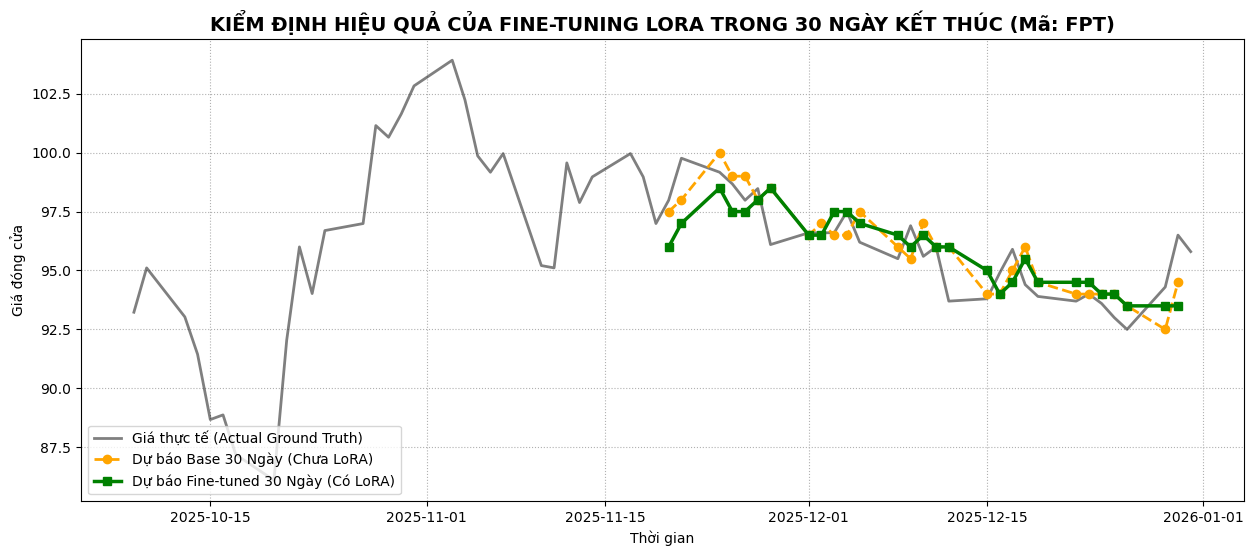

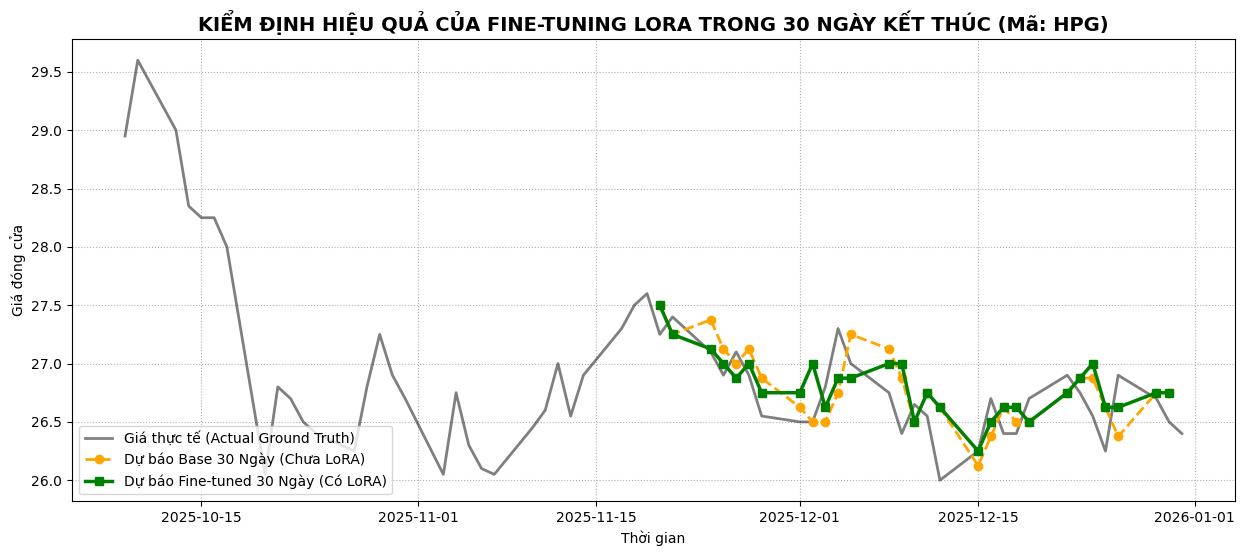

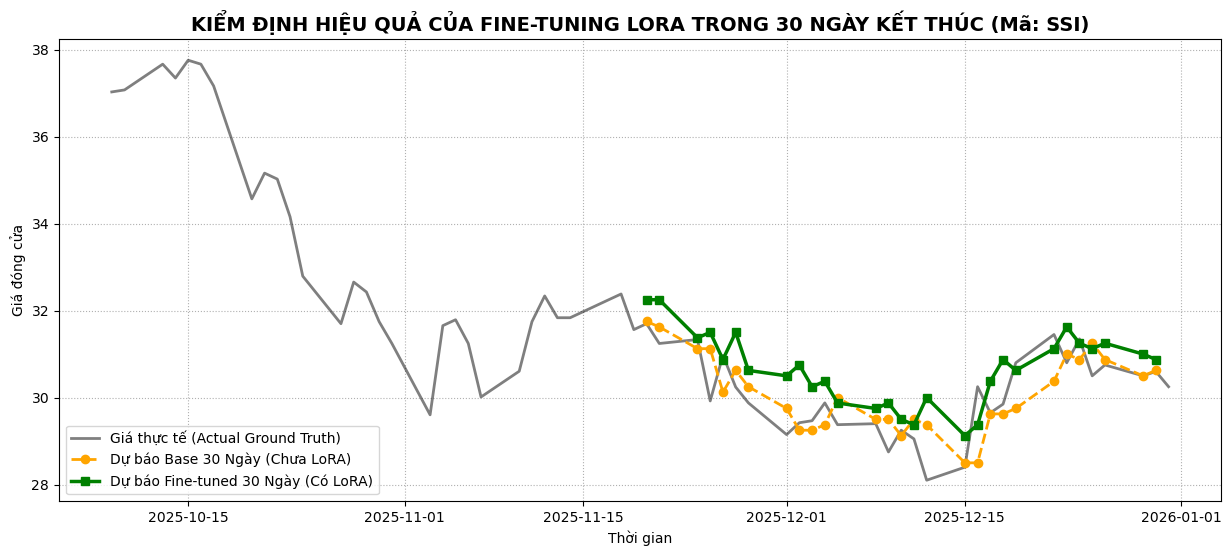

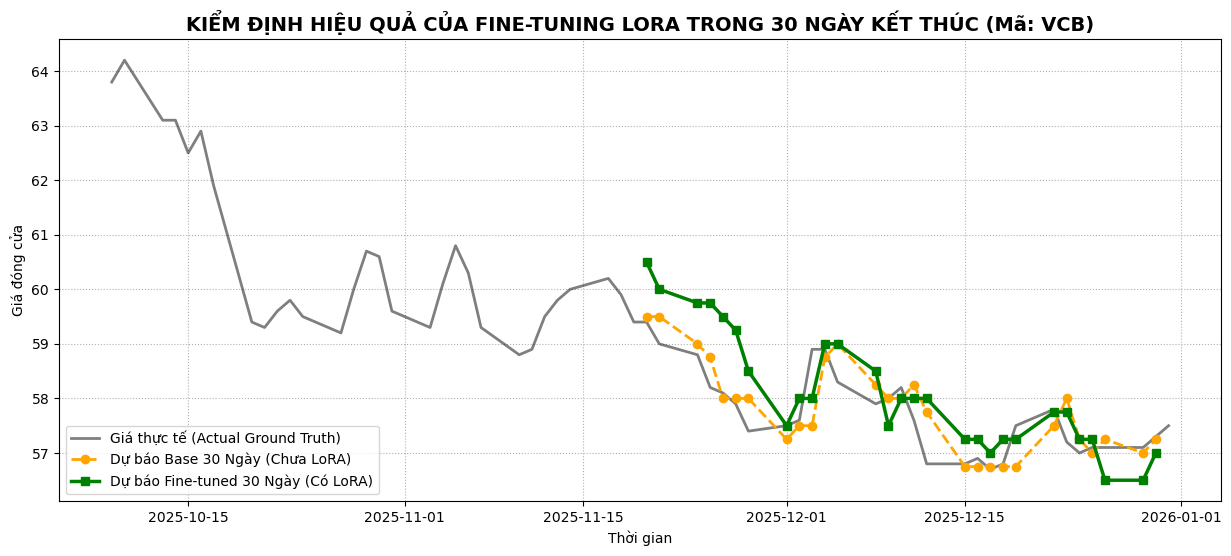

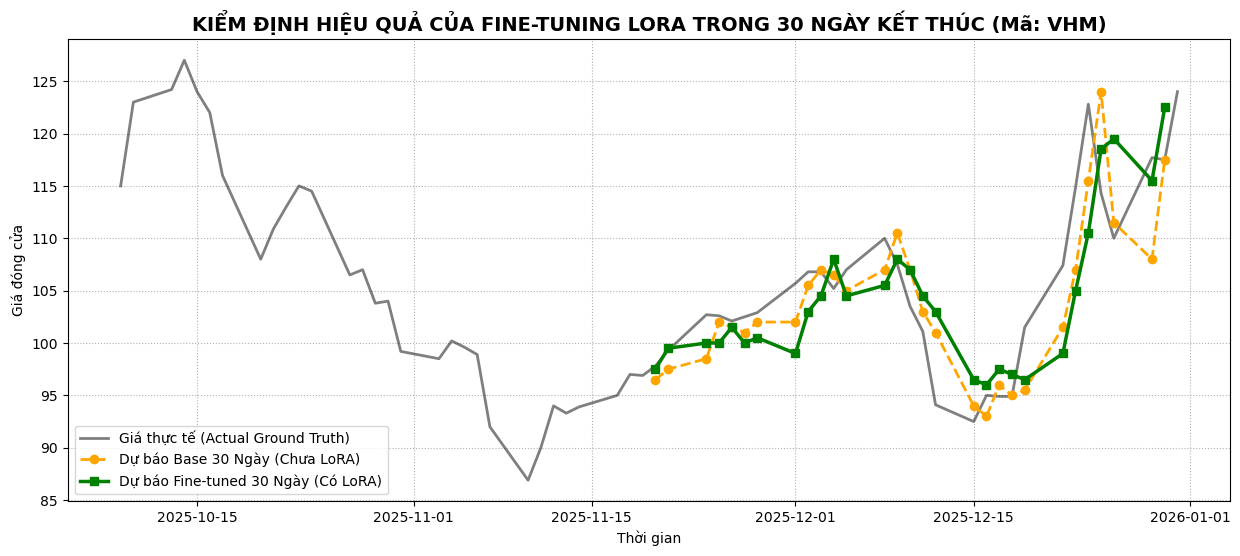

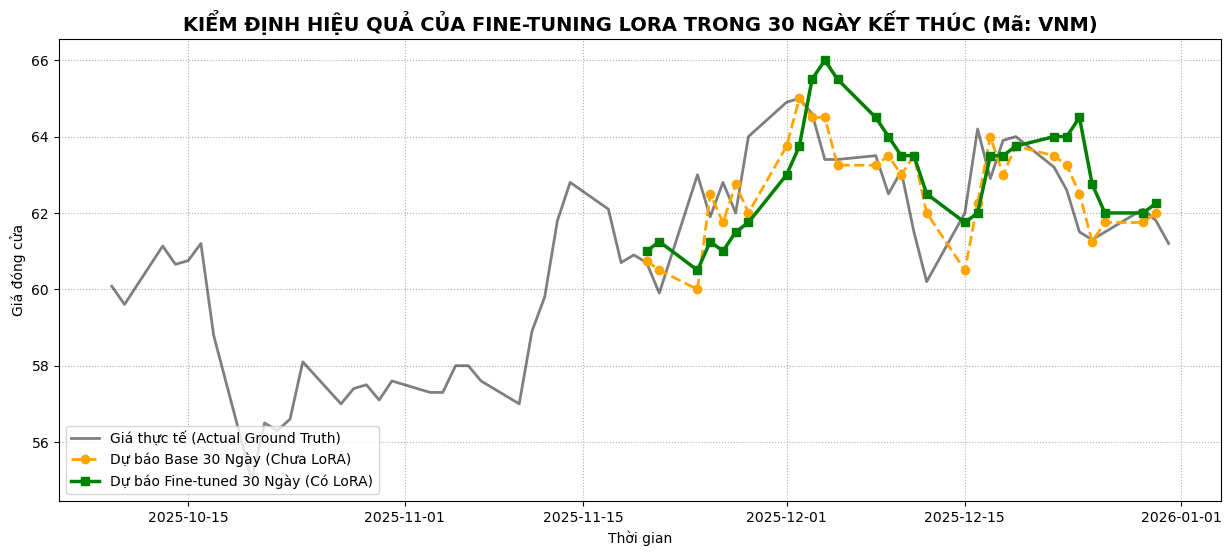

In [25]:
# ========== 6. TRỰC QUAN ĐÁNH GIÁ (BEFORE VS AFTER FINETUNING) ==========
def plot_compare(ticker, pre_train_pipe, post_train_pipe):
    plt.figure(figsize=(15, 6))

    days_to_show = 60 # Coi lại đường cong 60 ngày
    df_hist_viz = df_ticker[df_ticker['id'] == ticker].tail(days_to_show)
    plt.plot(df_hist_viz['timestamp'], df_hist_viz['Close'], label='Giá thực tế (Actual Ground Truth)', color='black', alpha=0.5, linewidth=2)
    
    # 2. DỰ BÁO TỪ BASE MODEL (Zero-shot) (Chưa đi train)
    # Lấy data Base Pred trực tiếp từ bảng eval_df ở bước 5 (tránh việc dùng for-loop predict lại lâu)
    base_ticker = eval_df[eval_df['id'] == ticker].sort_values('timestamp')
    
    plt.plot(base_ticker['timestamp'], base_ticker['Base_Predicted_Close'], 
             label='Dự báo Base 30 Ngày (Chưa LoRA)', color='Orange', linestyle='--', marker='o', linewidth=2)

    # 3. DỰ BÁO TỪ MODEL LORA (Đã nội địa hóa)
    finetuned_ticker = eval_df[eval_df['id'] == ticker].sort_values('timestamp')
    plt.plot(finetuned_ticker['timestamp'], finetuned_ticker['Finetuned_Predicted_Close'], 
             label='Dự báo Fine-tuned 30 Ngày (Có LoRA)', color='Green', linestyle='-', linewidth=2.5, marker='s')

    plt.title(f'KIỂM ĐỊNH HIỆU QUẢ CỦA FINE-TUNING LORA TRONG 30 NGÀY KẾT THÚC (Mã: {ticker})', fontweight='bold', fontsize=14)
    plt.xlabel('Thời gian')
    plt.ylabel('Giá đóng cửa')
    plt.grid(True, linestyle=":")
    plt.legend(loc='lower left')
    plt.show()

print("🎨 So sánh 2 đồ thị hiệu năng...")
tickers = list(df_test['id'].unique())[:6]
for tc in tickers:
    plot_compare(tc, pipeline, finetuned_pipeline)